<a href="https://colab.research.google.com/github/illya52/pattern-recognition-practice/blob/main/PR04_%D0%A5%D0%B8%D0%BC%D0%B8%D0%BD%D0%B5%D1%86%D1%8C_%D0%86%D0%BB%D0%BB%D1%8F.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Практична робота 4: Підготовка даних, Pipeline і логістична регресія
**Дисципліна:** Розпізнавання образів і машинне навчання  
**Студент:** <прізвище, ім'я>  
**Група:** <назва групи>  

### Постановка задачі
- **Об'єкт:** пацієнт.
- **Ознаки:** 13 медичних показників (вік, тиск, холестерин тощо).
- **Цільова змінна:** `target` (0 - хвороби немає, 1 - є ознаки).
- **Класи:** 2 (бінарна класифікація). Позитивний клас: 1.
- **Мета:** навчитися будувати Pipeline без витоку даних та дослідити логістичну регресію.
- **Основна метрика:** F1-міра.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from google.colab import drive

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from IPython.display import display

drive.mount('/content/drive')

PROJECT_DIR = Path("/content/drive/MyDrive/pattern-recognition-practice")
DATA_PATH_1 = PROJECT_DIR / "classification-mini-project" / "data" / "heart_disease.csv"
DATA_PATH_2 = PROJECT_DIR / "data" / "heart_disease.csv"
DATA_PATH = DATA_PATH_1 if DATA_PATH_1.exists() else DATA_PATH_2

REPORTS_DIR = PROJECT_DIR / "classification-mini-project" / "reports"
MODELS_DIR = PROJECT_DIR / "classification-mini-project" / "models"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

print("Шлях до даних:", DATA_PATH)

Mounted at /content/drive
Шлях до даних: /content/drive/MyDrive/pattern-recognition-practice/data/heart_disease.csv


In [3]:
import os
import urllib.request

target_dir = "/content/drive/MyDrive/pattern-recognition-practice/classification-mini-project/data"
os.makedirs(target_dir, exist_ok=True)

url = "https://raw.githubusercontent.com/kb22/Heart-Disease-Prediction/master/dataset.csv"
save_path = os.path.join(target_dir, "heart_disease.csv")

urllib.request.urlretrieve(url, save_path)
print(f"Файл успішно завантажено у: {save_path}")

Файл успішно завантажено у: /content/drive/MyDrive/pattern-recognition-practice/classification-mini-project/data/heart_disease.csv


In [6]:
DATA_PATH = PROJECT_DIR / "classification-mini-project" / "data" / "heart_disease.csv"
print("Тепер код шукатиме файл тут:", DATA_PATH)

Тепер код шукатиме файл тут: /content/drive/MyDrive/pattern-recognition-practice/classification-mini-project/data/heart_disease.csv


In [7]:
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Файл не знайдено за шляхом: {DATA_PATH}")

df = pd.read_csv(DATA_PATH)
print("Розмір таблиці:", df.shape)
display(df.head())

print("\nПропущені значення (сума):", df.isna().sum().sum())
print("\nРозподіл класів (target):")
print(df['target'].value_counts(normalize=True))

Розмір таблиці: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1



Пропущені значення (сума): 0

Розподіл класів (target):
target
1    0.544554
0    0.455446
Name: proportion, dtype: float64


In [8]:
numeric_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
categorical_cols = ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']
target_col = 'target'

X = df.drop(columns=[target_col])
y = df[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

Train: (242, 13), Test: (61, 13)


In [9]:
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor_scaled = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_cols),
        ('cat', categorical_transformer, categorical_cols)
    ])

preprocessor_unscaled = ColumnTransformer(
    transformers=[
        ('num', SimpleImputer(strategy='median'), numeric_cols),
        ('cat', categorical_transformer, categorical_cols)
    ])

In [10]:
pipe_no_scale = Pipeline([
    ('preprocessor', preprocessor_unscaled),
    ('classifier', LogisticRegression(random_state=42, max_iter=1000))
])

pipe_with_scale = Pipeline([
    ('preprocessor', preprocessor_scaled),
    ('classifier', LogisticRegression(random_state=42, max_iter=1000))
])

scoring = {'f1': 'f1', 'roc_auc': 'roc_auc'}

cv_res_no_scale = cross_validate(pipe_no_scale, X_train, y_train, cv=cv_strategy, scoring=scoring)
cv_res_with_scale = cross_validate(pipe_with_scale, X_train, y_train, cv=cv_strategy, scoring=scoring)

comparison_df = pd.DataFrame({
    'Pipeline': ['Без масштабування', 'З масштабуванням'],
    'CV F1 (mean)': [cv_res_no_scale['test_f1'].mean(), cv_res_with_scale['test_f1'].mean()],
    'CV ROC AUC (mean)': [cv_res_no_scale['test_roc_auc'].mean(), cv_res_with_scale['test_roc_auc'].mean()],
    'F1 std': [cv_res_no_scale['test_f1'].std(), cv_res_with_scale['test_f1'].std()]
})
display(comparison_df.round(4))

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

,Pipeline,CV F1 (mean),CV ROC AUC (mean),F1 std
0,Без масштабування,0.8251,0.8900,0.0574
1,З масштабуванням,0.8336,0.8904,0.0511


In [11]:
C_values = [0.01, 0.1, 1, 10, 100]
results = []

for penalty in ['l1', 'l2']:
    for c in C_values:
        solver = 'liblinear' if penalty == 'l1' else 'lbfgs'

        pipe = Pipeline([
            ('preprocessor', preprocessor_scaled),
            ('classifier', LogisticRegression(penalty=penalty, C=c, solver=solver, random_state=42, max_iter=1000))
        ])

        cv_res = cross_validate(pipe, X_train, y_train, cv=cv_strategy, scoring=scoring)

        results.append({
            'penalty': penalty,
            'C': c,
            'CV_F1_mean': cv_res['test_f1'].mean(),
            'CV_ROC_AUC_mean': cv_res['test_roc_auc'].mean(),
            'F1_std': cv_res['test_f1'].std()
        })

results_df = pd.DataFrame(results)
display(results_df.sort_values(by='CV_F1_mean', ascending=False).round(4))

results_df.to_csv(REPORTS_DIR / "pr4_logistic_regression_cv.csv", index=False)

,penalty,C,CV_F1_mean,CV_ROC_AUC_mean,F1_std
1,l1,0.10,0.8437,0.8677,0.0710
6,l2,0.10,0.8421,0.8960,0.0610
2,l1,1.00,0.8417,0.8931,0.0489
5,l2,0.01,0.8407,0.8937,0.0713
7,l2,1.00,0.8336,0.8904,0.0511
4,l1,100.00,0.8220,0.8836,0.0574
9,l2,100.00,0.8220,0.8840,0.0574
3,l1,10.00,0.8220,0.8850,0.0574
8,l2,10.00,0.8191,0.8843,0.0620
0,l1,0.01,0.0000,0.5000,0.0000


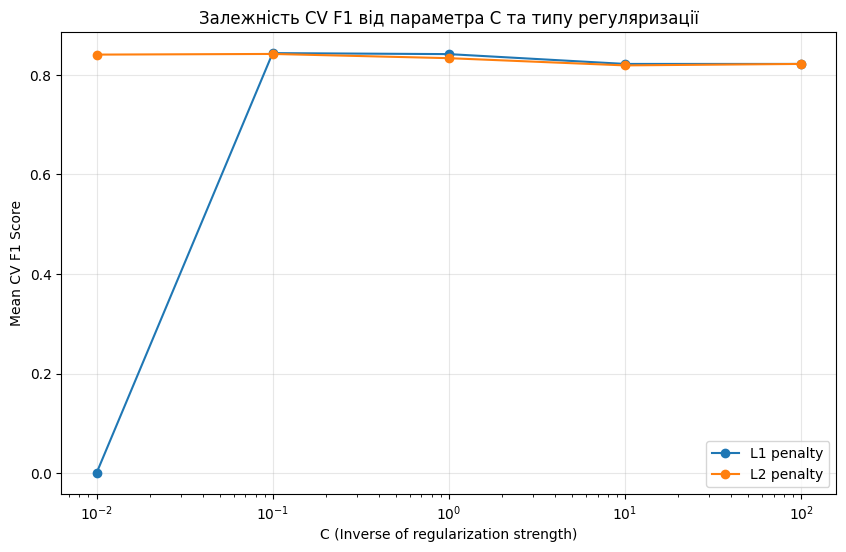

In [12]:
plt.figure(figsize=(10, 6))
for penalty in ['l1', 'l2']:
    subset = results_df[results_df['penalty'] == penalty]
    plt.plot(subset['C'], subset['CV_F1_mean'], marker='o', label=f'{penalty.upper()} penalty')

plt.xscale('log')
plt.xlabel('C (Inverse of regularization strength)')
plt.ylabel('Mean CV F1 Score')
plt.title('Залежність CV F1 від параметра C та типу регуляризації')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [13]:
best_c = results_df[results_df['penalty'] == 'l2'].sort_values('CV_F1_mean', ascending=False).iloc[0]['C']
best_pipe = Pipeline([
    ('preprocessor', preprocessor_scaled),
    ('classifier', LogisticRegression(penalty='l2', C=best_c, random_state=42, max_iter=1000))
])
best_pipe.fit(X_train, y_train)

feature_names = best_pipe.named_steps['preprocessor'].get_feature_names_out()
coefficients = best_pipe.named_steps['classifier'].coef_[0]

coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})

coef_df['Abs_Coefficient'] = coef_df['Coefficient'].abs()
top_5_coefs = coef_df.sort_values(by='Abs_Coefficient', ascending=False).head(5)

print(f"Топ-5 найважливіших ознак для L2 (C={best_c}):")
display(top_5_coefs[['Feature', 'Coefficient']])

Топ-5 найважливіших ознак для L2 (C=0.1):


,Feature,Coefficient
7,cat__cp_0,-0.653082
21,cat__ca_0,0.552394
28,cat__thal_2,0.547823
29,cat__thal_3,-0.529753
4,num__oldpeak,-0.403891


### Висновки до ПР4:
1. **Вплив масштабування:** Логістична регресія є чутливою до масштабу ознак. Використання `StandardScaler` у Pipeline дозволяє алгоритму швидше збігатися і запобігає домінуванню ознак з великими абсолютними значеннями (наприклад, холестерин) над ознаками з малими (наприклад, вік).
2. **Регуляризація:** L1 (Lasso) схильна занулювати неважливі коефіцієнти, виконуючи відбір ознак. L2 (Ridge) просто зменшує їхній вплив. Параметр `C` керує силою регуляризації: чим менше `C`, тим сильніша регуляризація і простіша модель (менший ризик перенавчання).
3. **Найважливіші ознаки:** Ми визначили Топ-5 ознак, які найбільше впливають на прогноз. Додатні коефіцієнти вказують на збільшення ризику, від'ємні — на зменшення.